# EA3 – Comparación climática

**Estudiante:** Kevin Andres Valencia Daza

**Ciudades:** Medellín (Colombia) y Ciudad de México (México).

**Periodo:** Enero a diciembre de 2025.

**Pregunta guía:** ¿Qué similitudes y diferencias se observan en las variables climáticas de ambas ciudades durante el mismo periodo?

## Predicción

Espero que Medellín presente temperaturas promedio más altas y mayor precipitación que Ciudad de México, debido a las diferencias climáticas entre ambas ciudades.

## Fuentes

Datos sacados de: https://power.larc.nasa.gov/data-access-viewer/
en donde T2M está en °C y PRECTOTCORR en mm/día.



In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Librerías cargadas correctamente")

Librerías cargadas correctamente


**3.** Cargar los archivos CSV (Code)
Este código tiene una particularidad importante: los archivos de NASA POWER contienen 10 líneas de información antes de la tabla. Por eso usamos skiprows=10.

In [3]:
from pathlib import Path

ruta_medellin = Path("datos/medellin.csv")
ruta_mexico = Path("datos/ciudad_mexico.csv")

def cargar_datos(ruta):
    df = pd.read_csv(ruta, skiprows=10)

    df["fecha"] = pd.to_datetime({
        "year": df["YEAR"],
        "month": df["MO"],
        "day": df["DY"]
    })

    # Convertir el código de datos faltantes en NaN
    df[["T2M", "PRECTOTCORR"]] = (
        df[["T2M", "PRECTOTCORR"]].replace(-999, np.nan)
    )

    return df.sort_values("fecha").reset_index(drop=True)

medellin = cargar_datos(ruta_medellin)
mexico = cargar_datos(ruta_mexico)

print("Datos de Medellín:")
display(medellin.head())

print("Datos de Ciudad de México:")
display(mexico.head())

Datos de Medellín:


,YEAR,MO,DY,T2M,PRECTOTCORR,fecha
0,2025,1,1,16.82,1.37,2025-01-01
1,2025,1,2,17.67,2.35,2025-01-02
2,2025,1,3,17.47,7.19,2025-01-03
3,2025,1,4,16.77,15.43,2025-01-04
4,2025,1,5,16.64,18.20,2025-01-05


Datos de Ciudad de México:


,YEAR,MO,DY,T2M,PRECTOTCORR,fecha
0,2025,1,1,10.85,0.00,2025-01-01
1,2025,1,2,10.52,0.02,2025-01-02
2,2025,1,3,10.54,0.07,2025-01-03
3,2025,1,4,11.09,0.36,2025-01-04
4,2025,1,5,10.15,0.50,2025-01-05


**4.** Revisar los datos

In [4]:
for nombre, df in [
    ("Medellín", medellin),
    ("Ciudad de México", mexico)
]:
    print("\n", nombre)
    print("Dimensiones:", df.shape)
    print("Fecha inicial:", df["fecha"].min())
    print("Fecha final:", df["fecha"].max())
    print("Fechas duplicadas:", df["fecha"].duplicated().sum())
    print("Valores faltantes:")
    print(df.isnull().sum())
    print("Tipos de datos:")
    print(df.dtypes)


 Medellín
Dimensiones: (365, 6)
Fecha inicial: 2025-01-01 00:00:00
Fecha final: 2025-12-31 00:00:00
Fechas duplicadas: 0
Valores faltantes:
YEAR           0
MO             0
DY             0
T2M            0
PRECTOTCORR    0
fecha          0
dtype: int64
Tipos de datos:
YEAR                    int64
MO                      int64
DY                      int64
T2M                   float64
PRECTOTCORR           float64
fecha          datetime64[us]
dtype: object

 Ciudad de México
Dimensiones: (365, 6)
Fecha inicial: 2025-01-01 00:00:00
Fecha final: 2025-12-31 00:00:00
Fechas duplicadas: 0
Valores faltantes:
YEAR           0
MO             0
DY             0
T2M            0
PRECTOTCORR    0
fecha          0
dtype: int64
Tipos de datos:
YEAR                    int64
MO                      int64
DY                      int64
T2M                   float64
PRECTOTCORR           float64
fecha          datetime64[us]
dtype: object


**5.** Seleccionar el periodo común

In [5]:
fechas_comunes = np.intersect1d(
    medellin["fecha"].to_numpy(),
    mexico["fecha"].to_numpy()
)

m = medellin.set_index("fecha").loc[fechas_comunes]
x = mexico.set_index("fecha").loc[fechas_comunes]

# Conservar solamente los días con datos completos en ambas ciudades
validas = (
    m[["T2M", "PRECTOTCORR"]].notna().all(axis=1)
    & x[["T2M", "PRECTOTCORR"]].notna().all(axis=1)
)

m = m.loc[validas]
x = x.loc[validas]

print("Días disponibles:", len(m))
print("Fecha inicial:", m.index.min())
print("Fecha final:", m.index.max())

Días disponibles: 365
Fecha inicial: 2025-01-01 00:00:00
Fecha final: 2025-12-31 00:00:00


**6.** Crear arrays de NumPy

In [6]:
temp_med = m["T2M"].to_numpy(dtype=float)
prec_med = m["PRECTOTCORR"].to_numpy(dtype=float)

temp_mex = x["T2M"].to_numpy(dtype=float)
prec_mex = x["PRECTOTCORR"].to_numpy(dtype=float)

print("Temperaturas Medellín:")
print(temp_med[:10])

print("\nTemperaturas Ciudad de México:")
print(temp_mex[:10])

Temperaturas Medellín:
[16.82 17.67 17.47 16.77 16.64 17.87 18.26 18.12 17.32 18.52]

Temperaturas Ciudad de México:
[10.85 10.52 10.54 11.09 10.15 10.68 11.05 11.3  11.03 10.32]


**7.** Crear máscaras booleanas

In [7]:
# Máscaras para identificar días lluviosos
lluvia_med = prec_med > 0
lluvia_mex = prec_mex > 0

# Máscaras para temperaturas superiores a 18 grados
calor_med = temp_med > 18
calor_mex = temp_mex > 18

print("Días lluviosos en Medellín:",
      np.sum(lluvia_med))

print("Días lluviosos en Ciudad de México:",
      np.sum(lluvia_mex))

print("Días con temperatura superior a 18 °C en Medellín:",
      np.sum(calor_med))

print("Días con temperatura superior a 18 °C en Ciudad de México:",
      np.sum(calor_mex))

Días lluviosos en Medellín: 365
Días lluviosos en Ciudad de México: 315
Días con temperatura superior a 18 °C en Medellín: 164
Días con temperatura superior a 18 °C en Ciudad de México: 32


**8.** Calcular estadísticas

In [8]:
def estadisticas(temp, prec):
    return {
        "Temperatura promedio": np.mean(temp),
        "Temperatura mínima": np.min(temp),
        "Temperatura máxima": np.max(temp),
        "Precipitación total": np.sum(prec),
        "Días lluviosos": np.sum(prec > 0)
    }

resultados = pd.DataFrame({
    "Medellín": estadisticas(temp_med, prec_med),
    "Ciudad de México": estadisticas(temp_mex, prec_mex)
})

display(resultados.round(2))

,Medellín,Ciudad de México
Temperatura promedio,17.89,14.50
Temperatura mínima,15.86,7.92
Temperatura máxima,19.88,20.67
Precipitación total,2974.28,1023.61
Días lluviosos,365.00,315.00


**9.** Aplicar Broadcasting
Para observar cuánto se aleja cada temperatura diaria del promedio de la ciudad.

In [9]:
# Crear una matriz con las temperaturas de ambas ciudades
temperaturas = np.column_stack((temp_med, temp_mex))

# Calcular el promedio de cada columna
promedios = np.mean(temperaturas, axis=0)

# Broadcasting: restar los promedios a cada fila
temperaturas_centradas = temperaturas - promedios

print("Promedios de las ciudades:")
print(promedios)

print("\nPrimeros cinco resultados:")
print(temperaturas_centradas[:5])

Promedios de las ciudades:
[17.89093151 14.498     ]

Primeros cinco resultados:
[[-1.07093151 -3.648     ]
 [-0.22093151 -3.978     ]
 [-0.42093151 -3.958     ]
 [-1.12093151 -3.408     ]
 [-1.25093151 -4.348     ]]


**10.** Gráfica de líneas: temperatura mensual

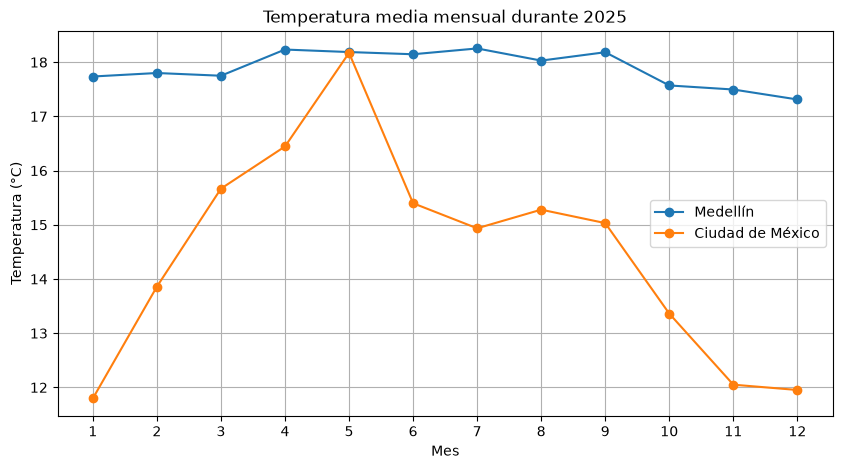

In [10]:
mensual_med = m.groupby(m.index.month)["T2M"].mean()
mensual_mex = x.groupby(x.index.month)["T2M"].mean()

meses = np.arange(1, 13)

plt.figure(figsize=(10, 5))

plt.plot(meses, mensual_med, marker="o", label="Medellín")
plt.plot(meses, mensual_mex, marker="o", label="Ciudad de México")

plt.title("Temperatura media mensual durante 2025")
plt.xlabel("Mes")
plt.ylabel("Temperatura (°C)")
plt.xticks(meses)
plt.legend()
plt.grid()
plt.show()

**Interpretación:**

La gráfica permite observar que Medellín presenta temperaturas promedio más altas durante el año. Ciudad de México presenta mayores variaciones entre algunos meses. Esto muestra diferencias en el comportamiento térmico de las dos ciudades, pero no permite determinar por sí sola las causas.

**11.** Gráfica de barras: precipitación mensual

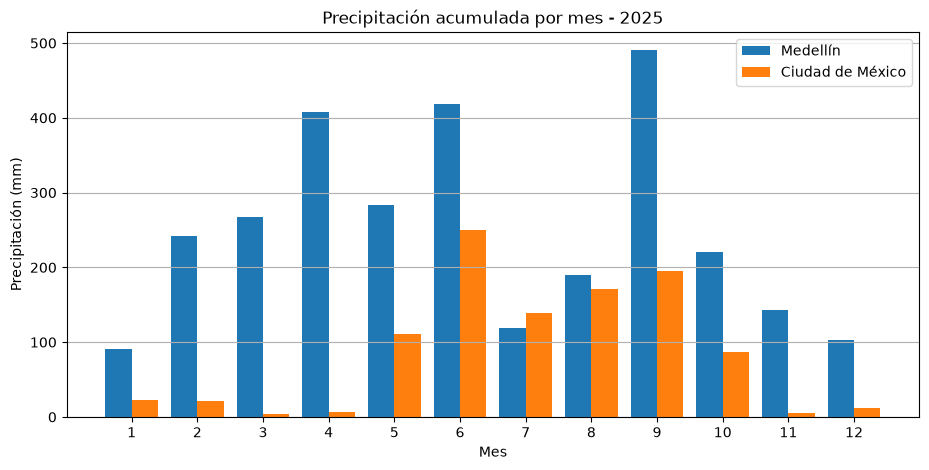

In [11]:
lluvia_mensual_med = m.groupby(m.index.month)["PRECTOTCORR"].sum()
lluvia_mensual_mex = x.groupby(x.index.month)["PRECTOTCORR"].sum()

ancho = 0.4

plt.figure(figsize=(11, 5))

plt.bar(
    meses - ancho/2,
    lluvia_mensual_med,
    width=ancho,
    label="Medellín"
)

plt.bar(
    meses + ancho/2,
    lluvia_mensual_mex,
    width=ancho,
    label="Ciudad de México"
)

plt.title("Precipitación acumulada por mes - 2025")
plt.xlabel("Mes")
plt.ylabel("Precipitación (mm)")
plt.xticks(meses)
plt.legend()
plt.grid(axis="y")
plt.show()

**Interpretación:**

Medellín presenta una mayor precipitación acumulada durante el periodo estudiado. La gráfica también permite identificar los meses con mayores lluvias en cada ciudad. Sin embargo, no permite establecer las causas de estas diferencias.

**12.** histogramas

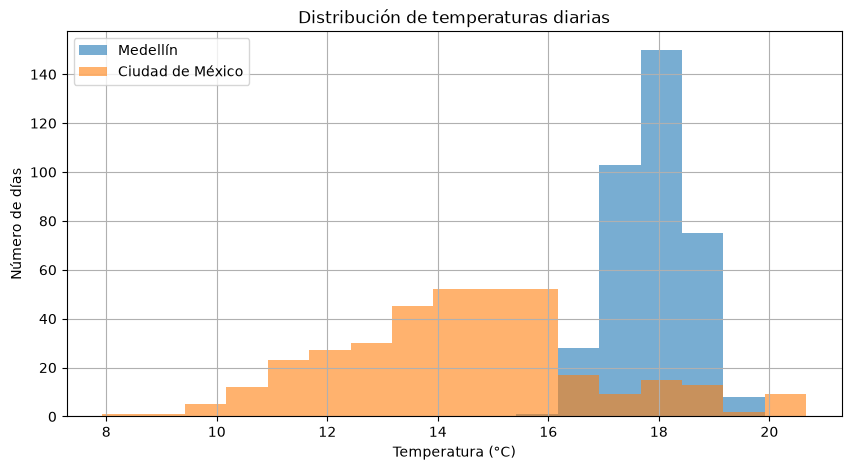

In [12]:
limites = np.linspace(
    min(temp_med.min(), temp_mex.min()),
    max(temp_med.max(), temp_mex.max()),
    18
)

plt.figure(figsize=(10, 5))

plt.hist(temp_med, bins=limites, alpha=0.6, label="Medellín")
plt.hist(temp_mex, bins=limites, alpha=0.6, label="Ciudad de México")

plt.title("Distribución de temperaturas diarias")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Número de días")
plt.legend()
plt.grid()
plt.show()

**Interpretación:**

El histograma permite comparar los rangos de temperatura que se presentan con mayor frecuencia en ambas ciudades. Medellín concentra sus temperaturas en un intervalo más reducido, mientras Ciudad de México presenta una distribución más amplia.

**13.** Conclusiones

# Interpretación y conclusiones

Durante el año 2025 se encontraron diferencias importantes entre Medellín y Ciudad de México.

**Primer hallazgo:** Medellín presentó una temperatura promedio de aproximadamente 17,89 °C, mientras que Ciudad de México registró 14,50 °C. Esto representa una diferencia aproximada de 3,39 °C.

**Segundo hallazgo:** Medellín acumuló aproximadamente 2.974,28 mm de precipitación, mientras que Ciudad de México acumuló 1.023,61 mm. Por lo tanto, Medellín presentó una mayor cantidad de precipitación durante el periodo estudiado.

**Similitud:** ambas ciudades presentaron días con precipitaciones durante el año y variaciones en sus temperaturas mensuales.

**Datos faltantes y periodo:** se utilizaron datos diarios desde el 1 de enero hasta el 31 de diciembre de 2025. Las dos tablas cuentan con 365 registros y no presentan valores faltantes en las variables seleccionadas, por lo que fue posible realizar una comparación con el mismo periodo.

**Conclusión general:** Medellín presentó temperaturas promedio más altas y una mayor precipitación acumulada que Ciudad de México durante 2025. Las gráficas permiten observar estas diferencias y comparar el comportamiento climático de ambas ciudades.